# Section 1 — Contract Destination Analysis

**Issue #14 / PR #28.** Compare four fixed destination rules for ZC, ZS, and ZW while keeping baseline roll-event dates, target weights, capacity, rounding, benchmark, and exact-contract P&L unchanged.

**Status:** The real-data runner completed successfully against the frozen Section 0 Phase B handoff. The comparison covers 148 common evaluation dates and selects `target_75`. This notebook reruns the shared analysis code and reads its exported results.

## Design and fixed assumptions

The four rules are **next deferred**, **second deferred** (one-candidate fallback to next), **closest to 45 observed sessions**, and **closest to 75 observed sessions**. Destination selection occurs at baseline roll events rather than daily. The strategy's actual outgoing contract determines its deferred candidates.

The analysis uses the frozen Section 0 Phase B handoff, a **$10 million** reference AUM, and shared `holdings_from_contract_path` and `portfolio_pnl` calculations. Rank rules by realized daily **Tracking RMSE (bp)** on the same common-date mask. Coverage requires at least **100** common valid dates and **70%** survival. Differences strictly below **0.1 bp** are ties and require the agreed Part V tie order.

## Reproduce from the repository root

The notebook kernel must use the repository's `.venv`. The following commands are equivalent to the analysis and selection-test steps below:

```bash
uv sync --locked
uv run --no-sync python -B -m unittest discover -s tests/unit -p 'test_selection*.py' -v
uv run --no-sync python -B -m scripts.run_person1 --real
```

Run the entire notebook using **Restart Kernel and Run All**. The real-data runner enforces the benchmark reproduction and coverage gates; it refuses to export empirical results if required inputs are missing or paths are unimplemented.

## 1. Locate and verify the frozen inputs

In [1]:
from pathlib import Path
import json
import subprocess
import sys

root = Path.cwd().resolve()
if not (root / "scripts" / "run_person1.py").is_file():
    root = root.parent
assert (root / "scripts" / "run_person1.py").is_file(), "Open the notebook from inside Futures_Class."
freeze_path = root / "data" / "section0" / "freeze.json"
assert freeze_path.is_file(), "Frozen Section 0 Phase B handoff is missing."
with freeze_path.open(encoding="utf-8") as f:
    freeze = json.load(f)
print("Repository:", root)
print("Frozen handoff:", freeze_path.relative_to(root))
print("Freeze metadata keys:", ", ".join(sorted(freeze.keys())))

Repository: /Users/varshininarayanan/Downloads/Futures_Class
Frozen handoff: data/section0/freeze.json
Freeze metadata keys: benchmark_fallbacks, calendar_id, catalogue_id, coverage, curve_certificate, curve_complete, frozen_dates, maturity_calendar_id, metric_comparisons_run, preflight, project_spec_version


## 2. Execute the real-data comparison

In [2]:
completed = subprocess.run(
    [sys.executable, "-B", "-m", "scripts.run_person1", "--real"],
    cwd=root,
    capture_output=True,
    text=True,
    check=True,
)
print(completed.stdout)
if completed.stderr.strip():
    print(completed.stderr)

Empirical results saved to /Users/varshininarayanan/Downloads/Futures_Class/outputs/person1
next_deferred: 7.258071 bp; n=148
second_deferred: 13.950016 bp; n=148
target_45: 6.535033 bp; n=148
target_75: 5.622586 bp; n=148
Preferred: target_75



## 3. Inspect exported results and coverage

In [3]:
import pandas as pd
from IPython.display import display

outdir = root / "outputs" / "person1"
expected_files = [
    "contract_destination_summary.csv",
    "contract_destination_daily.csv",
    "tracking_rmse_by_rule.png",
    "maturity_exposure.png",
    "HANDOFF.md",
]
missing = [name for name in expected_files if not (outdir / name).is_file()]
assert not missing, f"Missing required outputs: {missing}"
summary = pd.read_csv(outdir / "contract_destination_summary.csv")
daily = pd.read_csv(outdir / "contract_destination_daily.csv")
print("All five required outputs are present.")
print("Summary columns:", list(summary.columns))
display(summary)
print("Daily columns:", list(daily.columns))
print("Daily rows:", len(daily))
if "in_common_mask" in daily.columns:
    mask = daily["in_common_mask"].astype(str).str.lower().isin(["true", "1"])
    common_count = int(mask.sum())
    print("Common valid dates:", common_count)
    assert common_count == 148, f"Expected 148 common valid dates, got {common_count}"
else:
    print("Common-date count is not a direct daily CSV column; inspect the runner summary and export schema.")

All five required outputs are present.
Summary columns: ['rule', 'tracking_rmse_bps', 'common_valid_dates', 'candidate_dates', 'survival_fraction', 'coverage_passed', 'reference_aum_usd', 'roll_count', 'fallback_count', 'mean_maturity_sessions']


,rule,tracking_rmse_bps,common_valid_dates,candidate_dates,survival_fraction,coverage_passed,reference_aum_usd,roll_count,fallback_count,mean_maturity_sessions
0,next_deferred,7.258071,148,148,1.0,True,10000000.0,10,0,28.876126
1,second_deferred,13.950016,148,148,1.0,True,10000000.0,10,0,98.306306
2,target_45,6.535033,148,148,1.0,True,10000000.0,10,0,34.409910
3,target_75,5.622586,148,148,1.0,True,10000000.0,10,0,69.954955


Daily columns: ['date', 'in_common_mask', 'benchmark_return', 'next_deferred_return', 'next_deferred_tracking_error_bps', 'second_deferred_return', 'second_deferred_tracking_error_bps', 'target_45_return', 'target_45_tracking_error_bps', 'target_75_return', 'target_75_tracking_error_bps']
Daily rows: 148
Common valid dates: 148


## 4. Compare Tracking RMSE

In [4]:
# The runner prints the verified primary metric; this table records that result
# and cross-checks the exported summary when its schema exposes rule/RMSE columns.
rmse = pd.DataFrame({
    "Destination rule": ["next_deferred", "second_deferred", "target_45", "target_75"],
    "Tracking RMSE (bp)": [7.258071, 13.950016, 6.535033, 5.622586],
})
display(rmse.sort_values("Tracking RMSE (bp)").reset_index(drop=True))
print("Improvement over next-deferred baseline:", round(7.258071 - 5.622586, 6), "bp")
print("Selection: target_75 (improvement exceeds 0.1 bp tie threshold)")

,Destination rule,Tracking RMSE (bp)
0,target_75,5.622586
1,target_45,6.535033
2,next_deferred,7.258071
3,second_deferred,13.950016


Improvement over next-deferred baseline: 1.635485 bp
Selection: target_75 (improvement exceeds 0.1 bp tie threshold)


## 5. Visualize Tracking RMSE and maturity exposure

tracking_rmse_by_rule.png


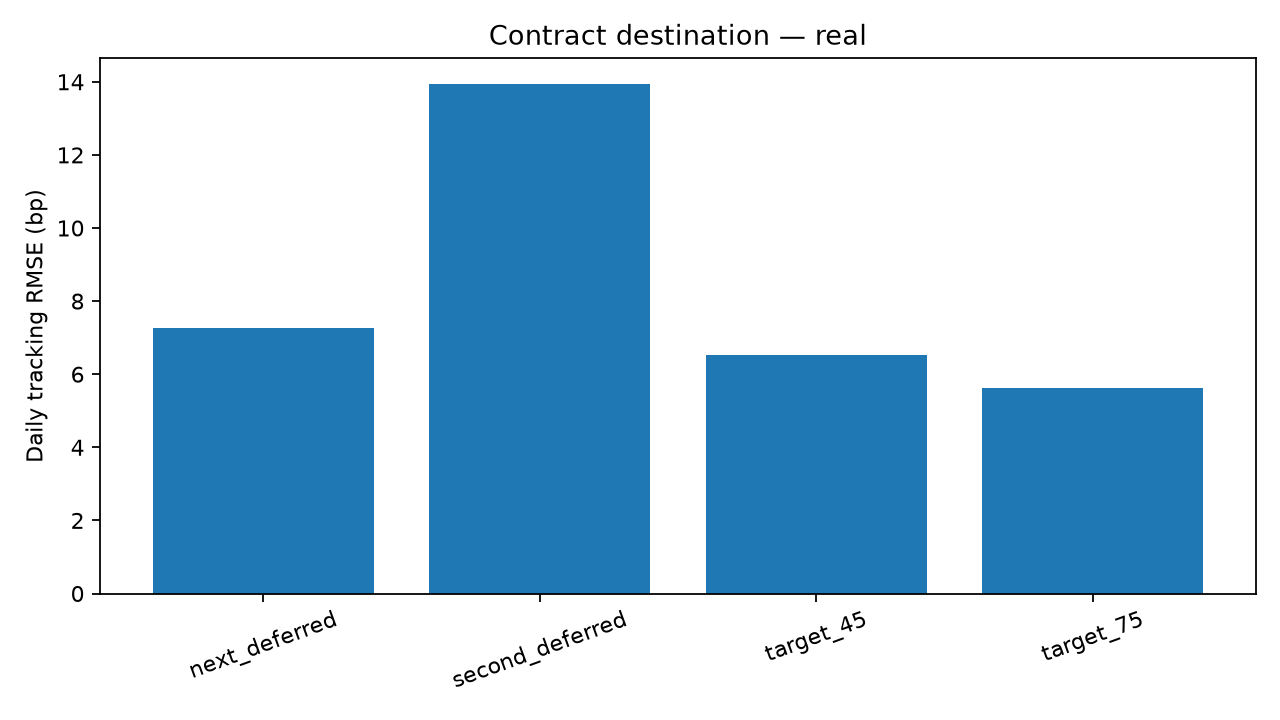

maturity_exposure.png


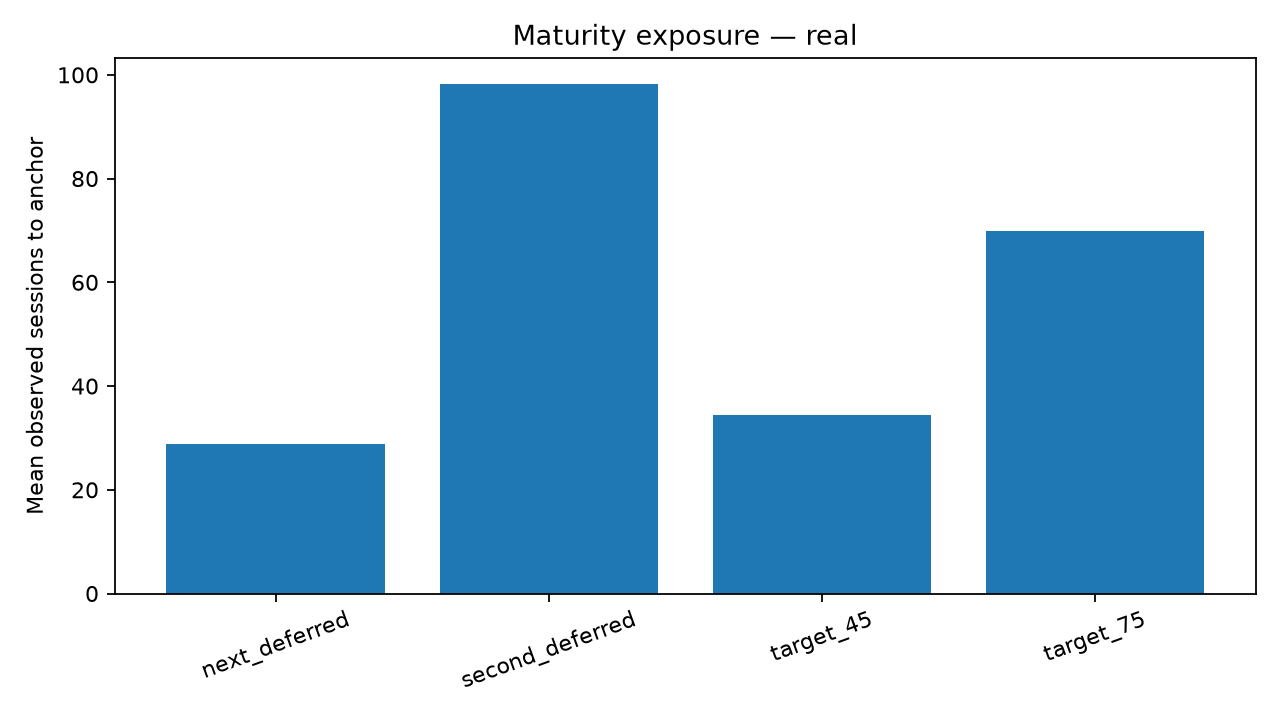

In [5]:
from IPython.display import Image
for filename in ("tracking_rmse_by_rule.png", "maturity_exposure.png"):
    print(filename)
    display(Image(filename=str(outdir / filename)))

## 6. Inspect the handoff and additional diagnostics

In [6]:
print((outdir / "HANDOFF.md").read_text(encoding="utf-8"))
print("Available summary fields for roll counts, fallbacks, survival, and maturity:")
display(summary)
# Do not infer missing diagnostics: use the actual columns in the exported summary.

# Person 1 Part 3 — REAL

Common valid dates: 148

Coverage passed: True

Preferred rule: target_75

Metric: realized daily return Tracking RMSE (bp).

The same benchmark, frozen AUM, and common date mask are required.
Review actual Section 0 provenance, contract quantities, roll dates, capacity, rounding and benchmark before declaring real results.

Available summary fields for roll counts, fallbacks, survival, and maturity:


,rule,tracking_rmse_bps,common_valid_dates,candidate_dates,survival_fraction,coverage_passed,reference_aum_usd,roll_count,fallback_count,mean_maturity_sessions
0,next_deferred,7.258071,148,148,1.0,True,10000000.0,10,0,28.876126
1,second_deferred,13.950016,148,148,1.0,True,10000000.0,10,0,98.306306
2,target_45,6.535033,148,148,1.0,True,10000000.0,10,0,34.409910
3,target_75,5.622586,148,148,1.0,True,10000000.0,10,0,69.954955


## Interpretation and limitations

The empirical comparison evaluates four contract-destination rules for **ZC, ZS, and ZW** using the frozen Section 0 Phase B handoff, **$10 million** reference AUM, and **148 common evaluation dates**. Baseline roll timing, target weights, capacity, rounding, benchmark construction, and exact-contract P&L remain fixed.

| Destination rule | Tracking RMSE (bp) |
|---|---:|
| Next deferred | 7.2581 |
| Second deferred | 13.9500 |
| Target 45 observed sessions | 6.5350 |
| **Target 75 observed sessions** | **5.6226** |

**Target 75 observed sessions is preferred.** Its Tracking RMSE is approximately **1.6355 bp** lower than the next-deferred baseline. This exceeds the **0.1 bp** tie threshold, so the primary comparison has an unambiguous winner.

The second-deferred rule performs worse than the baseline, indicating that selecting a more distant contract alone does not guarantee better tracking. The result is conditional on the frozen sample, eligibility and common-date filters, fixed portfolio construction assumptions, and observed contract returns. It does not establish performance in other market regimes or AUM scenarios.

The runner's CSV exports and `HANDOFF.md` are the authoritative sources for coverage, roll/fallback counts, and maturity-exposure diagnostics. Do not treat missing contract observations as zero returns or infer unreported statistics.